# Kingston University Coursework Brief 2026 2027

### Module Title: Applied Data Programming
### Assessment Title: Research Report and Visualisation

#### Team is :
##### Aruna Mahagamage
##### Isham Sally
##### Mihiri 
##### Nilanga

In [1]:
# Import required Library
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

In [2]:
# 1. Load dataset
df = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)

#### Current Column Names and There Name Consistency Diffrences (Not Follow up correct standerd for naming convention)

In [3]:
print("Original headers:", df.columns.tolist())

Original headers: ['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']


In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)
pd.set_option('display.min_rows', 10)
display(df)

,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,Crime Name3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,20904.0,MCPD,Government Building,I,3I1,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - BUSINESS,GERMANTOWN,13000 BLK MIDDLEBROOK RD,GERMANTOWN,MD,20874.0,MCPD,Retail - Drug Store/Pharmacy,N,5N1,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,20904.0,MCPD,Residence - Other,I,3I1,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,MONTGOMERY VILLAGE,200 BLK PARAMOUNT PARK DR,GAITHERSBURG,MD,20879.0,MCPD,Residence -Townhouse/Duplex,P,6P2,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,10100 BLK NEW HAMPSHIRE AVE,SILVER SPRING,MD,20903.0,MCPD,Restaurant,I,3I3,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508101,201089700,2308,16036427,NaN,07/01/2016 12:00:00 AM,07/05/2016 12:00:00 AM,23D,1,Crime Against Property,Theft from Building,LARCENY - FROM BLDG,BETHESDA,4100 BLK LELAND ST,CHEVY CHASE,MD,20815.0,MCPD,Residence - Single Family,D,2D1,036,4100.0,NaN,LELAND,NaN,ST,38.98565,-77.0818,2D,"(38.9857, -77.0818)"
508102,201248224,9105,190033731,07/16/2019 10:55:43 AM,07/01/2016 12:00:00 AM,NaN,90Z,1,Crime Against Society,All Other Offenses,LOST PROPERTY,ROCKVILLE,1 BLK MONROE PL,ROCKVILLE,MD,20850.0,MCPD,Residence - Apartment/Condo,A,1A3,276,1.0,NaN,MONROE,NaN,PL,39.08354,-77.1469,1D,"(39.0835, -77.1469)"
508103,201100330,2589,16048345,NaN,07/01/2016 12:00:00 AM,07/31/2016 12:00:00 AM,250,1,Crime Against Property,Counterfeiting/Forgery,FORGERY (DESCRIBE OFFENSE),ROCKVILLE,1 BLK COURTHOUSE SQ,ROCKVILLE,MD,20850.0,MCPD,Residence - Garage,A,1A3,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)"
508104,201103549,2699,16053730,NaN,07/01/2016 12:00:00 AM,09/30/2016 11:59:00 PM,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,FRAUD (DESCRIBE OFFENSE),ROCKVILLE,13100 BLK OKINAWA AVE,ROCKVILLE,MD,20851.0,RCPD,Residence - Single Family,A,1A2,298,13100.0,NaN,OKINAWA,NaN,AVE,39.07045,-77.1214,1D,"(39.0705, -77.1214)"


#### Check First row is Headers

In [5]:
# If the first row was actually data (no header), reload with header=None
if str(df.columns[0]).strip().isdigit():
    df = pd.read_csv("dataset_coursework1-1.csv", header=None, low_memory=False)
print(df.columns[0])

Incident ID


#### Add standerd for naming convention

In [6]:
# Assign standard 30-column NIBRS names by position
# The data set Titles are not follow up standerd to written names
# Assign Column Names to Python List
canonical_cols = [
    "Incident ID", "Offense Code", "CR Number", "Dispatch Date/Time",
    "Start Date/Time", "End Date/Time", "NIBRS Code", "Victims",
    "Crime Name 1", "Crime Name 2", "Crime Name 3", "Police District Name",
    "Block Address", "City", "State", "Zip Code", "Agency", "Place",
    "Sector", "Beat", "PRA", "Address Number", "Street Prefix",
    "Street Name", "Street Suffix", "Street Type", "Latitude",
    "Longitude", "Police District Number", "Geolocation"
]

#### Replace Columns Name Standerd Patterns

In [7]:
if df.shape[1] == 30:
    df.columns = canonical_cols
else:
    raise ValueError(f"Expected 30 columns, found {df.shape[1]}. Check separator/encoding.")

In [8]:
print("Modified standerd headers:", df.columns.tolist())

Modified standerd headers: ['Incident ID', 'Offense Code', 'CR Number', 'Dispatch Date/Time', 'Start Date/Time', 'End Date/Time', 'NIBRS Code', 'Victims', 'Crime Name 1', 'Crime Name 2', 'Crime Name 3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Geolocation']


In [9]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)
pd.set_option('display.min_rows', 10)
display(df)

,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,Crime Name 3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,20904.0,MCPD,Government Building,I,3I1,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - BUSINESS,GERMANTOWN,13000 BLK MIDDLEBROOK RD,GERMANTOWN,MD,20874.0,MCPD,Retail - Drug Store/Pharmacy,N,5N1,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,20904.0,MCPD,Residence - Other,I,3I1,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,MONTGOMERY VILLAGE,200 BLK PARAMOUNT PARK DR,GAITHERSBURG,MD,20879.0,MCPD,Residence -Townhouse/Duplex,P,6P2,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,10100 BLK NEW HAMPSHIRE AVE,SILVER SPRING,MD,20903.0,MCPD,Restaurant,I,3I3,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508101,201089700,2308,16036427,NaN,07/01/2016 12:00:00 AM,07/05/2016 12:00:00 AM,23D,1,Crime Against Property,Theft from Building,LARCENY - FROM BLDG,BETHESDA,4100 BLK LELAND ST,CHEVY CHASE,MD,20815.0,MCPD,Residence - Single Family,D,2D1,036,4100.0,NaN,LELAND,NaN,ST,38.98565,-77.0818,2D,"(38.9857, -77.0818)"
508102,201248224,9105,190033731,07/16/2019 10:55:43 AM,07/01/2016 12:00:00 AM,NaN,90Z,1,Crime Against Society,All Other Offenses,LOST PROPERTY,ROCKVILLE,1 BLK MONROE PL,ROCKVILLE,MD,20850.0,MCPD,Residence - Apartment/Condo,A,1A3,276,1.0,NaN,MONROE,NaN,PL,39.08354,-77.1469,1D,"(39.0835, -77.1469)"
508103,201100330,2589,16048345,NaN,07/01/2016 12:00:00 AM,07/31/2016 12:00:00 AM,250,1,Crime Against Property,Counterfeiting/Forgery,FORGERY (DESCRIBE OFFENSE),ROCKVILLE,1 BLK COURTHOUSE SQ,ROCKVILLE,MD,20850.0,MCPD,Residence - Garage,A,1A3,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)"
508104,201103549,2699,16053730,NaN,07/01/2016 12:00:00 AM,09/30/2016 11:59:00 PM,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,FRAUD (DESCRIBE OFFENSE),ROCKVILLE,13100 BLK OKINAWA AVE,ROCKVILLE,MD,20851.0,RCPD,Residence - Single Family,A,1A2,298,13100.0,NaN,OKINAWA,NaN,AVE,39.07045,-77.1214,1D,"(39.0705, -77.1214)"


#### How many rows and Columns in the Data set

In [10]:
total_raw_rows = len(df)
print(f"Total raw rows: {total_raw_rows:,} | Columns: {df.shape[1]}")

Total raw rows: 508,106 | Columns: 30


#### What is Define in the data set Column Naming

In [11]:
# What Define in the data set Column Naming
df_colomun_defination = pd.read_csv("montgomery_county_crime_data_dictionary.csv", low_memory=False)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 30)
pd.set_option('display.min_rows', 30)

display(df_colomun_defination)

,Col_Number,Original Data set Naming,Canonical_Name,Technical_Definition_and_Analytical_Role
0,1,Incident ID,Incident ID,"Unique system-generated primary key for each individual offense entry in the database (467,601 unique values; 40,505 exact duplicates removed during cleaning)."
1,2,Offence Code,Offense Code,Internal Montgomery County statutory/local offense classification code (360 unique codes) mapping to specific state or county criminal violations.
2,3,CR Number,CR Number,"Case Report Number (467,534 unique values). Groups offenses belonging to the same police investigation/incident report."
3,4,Dispatch Date / Time,Dispatch Date/Time,"Timestamp when Emergency Communications (911/CAD) assigned and notified a police unit to respond. Missing in 14.45% of records (73,405 rows) where reports were filed via walk-in, phone, or online without unit dispatch."
4,5,Start_Date_Time,Start Date/Time,Reported or estimated date and time when the criminal offense began (supplied by the reporting party). Complete (0% missing) and serves as the primary temporal anchor.
5,6,End_Date_Time,End Date/Time,"Reported or estimated date and time when the offense concluded (e.g., the end of an overnight window when a vehicle was parked). Null in 55.59% of rows for instantaneous offenses."
6,7,NIBRS Code,NIBRS Code,"Standardized federal FBI National Incident-Based Reporting System offense code (54 unique categories, e.g., 13B for Simple Assault, 23F for Theft from Motor Vehicle)."
7,8,Victims,Victims,Count of individual victims associated with that specific offense row (ranges from 1 to 10 in this dataset).
8,9,Crime Name1,Crime Name 1,"Highest-level NIBRS crime taxonomy (4 values: Crime Against Person, Crime Against Property, Crime Against Society, and Not a Crime / Other)."
9,10,Crime Name2,Crime Name 2,"Intermediate NIBRS offense group (54 categories, e.g., Simple Assault, All Other Larceny, Drug/Narcotic Violations), matching NIBRS Code 1-to-1."


#### Data Quality

In [12]:
# 2. Initial Data Quality Audit (Quantifying Missingness & Noise)
audit = pd.DataFrame({
    "data_type": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().sum() / total_raw_rows * 100).round(2),
    "unique_values": df.nunique()
})
print("\n--- Missingness & Cardinality Audit ---")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 40)
pd.set_option('display.min_rows', 40)
#print(audit)
display(audit)
#pd.to_csv("supplementary_offense_codes_360.csv", index=False)


--- Missingness & Cardinality Audit ---


,data_type,missing_count,missing_pct,unique_values
Incident ID,int64,0,0.00,467601
Offense Code,object,0,0.00,360
CR Number,int64,0,0.00,467534
Dispatch Date/Time,object,73405,14.45,397963
Start Date/Time,object,0,0.00,372500
End Date/Time,object,282444,55.59,157941
NIBRS Code,object,0,0.00,54
Victims,int64,0,0.00,10
Crime Name 1,object,0,0.00,4
Crime Name 2,object,0,0.00,54


#### Some Cordinate is missing and google map navigate to sea side. becourse of 0.0 cordinates

In [13]:
# Ensure numeric types for Latitude/Longitude/Victims
for num_col in ["Latitude", "Longitude", "Victims"]:
    df[num_col] = pd.to_numeric(df[num_col], errors="coerce")

zero_coords = ((df["Latitude"] == 0.0) | (df["Longitude"] == 0.0)).sum()
null_coords = (df["Latitude"].isna() | df["Longitude"].isna()).sum()
print(f"\nZeroed Coordinates (0.0): {zero_coords:,} ({zero_coords/total_raw_rows*100:.2f}%)")
print(f"Null Coordinates (NaN):   {null_coords:,} ({null_coords/total_raw_rows*100:.2f}%)")


Zeroed Coordinates (0.0): 24,648 (4.85%)
Null Coordinates (NaN):   0 (0.00%)


In [14]:
# 3. Date Parsing & Temporal Consistency Check
date_cols = ["Dispatch Date/Time", "Start Date/Time", "End Date/Time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

invalid_end = (df["End Date/Time"] < df["Start Date/Time"]).sum()
out_of_scope = ((df["Start Date/Time"] < "2016-07-01") | (df["Start Date/Time"] > "2026-09-10 23:59:59")).sum()
print(f"End Date < Start Date anomalies: {invalid_end:,} ({invalid_end/total_raw_rows*100:.2f}%)")
print(f"Out-of-scope timestamps:        {out_of_scope:,} ({out_of_scope/total_raw_rows*100:.2f}%)")

End Date < Start Date anomalies: 8,418 (1.66%)
Out-of-scope timestamps:        228 (0.04%)


In [28]:
# Load the approved shared dataset
#df_shared = pd.read_parquet("data/processed/cw1_shared_v1.parquet")
df_rq = df.copy()

# Select relevant columns for crime pattern & offense code analysis
cols = [
    "Incident ID", "Offense Code", "NIBRS Code",
    "Crime Name 1", "Crime Name 2", "Crime Name 3",
    "Police District Name", "Start Date/Time"
]
df_analysis = df_rq[cols].copy()

# Extract Year (exclude partial years 2016 and 2026 when measuring full-year growth rates)
df_analysis["Year"] = df_analysis["Start Date/Time"].dt.year

# 1. Top 10 Offense Codes & NIBRS Codes overall (2016–2026)
top_offenses = (
    df_analysis.groupby(["Offense Code", "NIBRS Code", "Crime Name 2", "Crime Name 3"])
    .size()
    .reset_index(name="Offense_Count")
    .sort_values("Offense_Count", ascending=False)
)
top_offenses["Share_%"] = (top_offenses["Offense_Count"] / len(df_analysis) * 100).round(2)
display(top_offenses.head(10))

# 2. Fastest-growing offenses across full calendar years (2017 vs. 2025)
df_full_years = df_analysis[df_analysis["Year"].between(2017, 2025)]
yearly_counts = (
    df_full_years.groupby(["Crime Name 2", "Year"])
    .size()
    .unstack(fill_value=0)
)

# Filter offenses with at least 500 cases in 2017 to avoid small-base distortion
significant_crimes = yearly_counts[yearly_counts[2017] >= 500].copy()
significant_crimes["Growth_Rate_%"] = (
    (significant_crimes[2025] - significant_crimes[2017]) / significant_crimes[2017] * 100
).round(2)

display(significant_crimes[[2017, 2021, 2025, "Growth_Rate_%"]].sort_values("Growth_Rate_%", ascending=False).head(10))

,Offense Code,NIBRS Code,Crime Name 2,Crime Name 3,Offense_Count,Share_%
105,2305,23F,Theft From Motor Vehicle,LARCENY - FROM AUTO,41308,8.13
103,2303,23C,Shoplifting,LARCENY - SHOPLIFTING,35011,6.89
356,9199,90Z,All Other Offenses,POLICE INFORMATION,33174,6.53
74,1399,13B,Simple Assault,ASSAULT - 2ND DEGREE,31826,6.26
115,2399,23H,All other Larceny,LARCENY (DESCRIBE OFFENSE),20699,4.07
161,2902,290,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - PRIVATE,19814,3.90
355,9113,90Z,All Other Offenses,MENTAL ILLNESS - EMERGENCY PETITION,19739,3.88
299,5404,90D,Driving Under the Influence,DRIVING UNDER THE INFLUENCE LIQUOR,19420,3.82
347,9105,90Z,All Other Offenses,LOST PROPERTY,17917,3.53
119,2404,240,Motor Vehicle Theft,AUTO THEFT - VEHICLE THEFT,17262,3.40


Year,2017,2021,2025,Growth_Rate_%
Crime Name 2,,,,
Motor Vehicle Theft,909,1433,2323,155.56
Theft of Motor Vehicle Parts or Accessories,812,1632,1532,88.67
Shoplifting,2599,2435,4742,82.45
Identity Theft,766,2677,1120,46.21
Aggravated Assault,648,827,765,18.06
False Pretenses/Swindle/Confidence Game,925,1193,1004,8.54
Simple Assault,3489,3401,3770,8.05
Runaway,683,432,733,7.32
All Other Offenses,12204,11920,12734,4.34


In [15]:
# 4. Cleaning & Transformation
df_clean = df.copy()
df_clean.loc[(df_clean["Latitude"] == 0.0) | (df_clean["Longitude"] == 0.0), ["Latitude", "Longitude"]] = np.nan

df_clean["Dispatch Status"] = np.where(df_clean["Dispatch Date/Time"].isna(), "Non-Dispatched", "Dispatched")
df_clean["Crime Name 1"] = df_clean["Crime Name 1"].fillna("Unknown / Unclassified")
df_clean["Police District Name"] = df_clean["Police District Name"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")
df_clean["City"] = df_clean["City"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")

df_clean.loc[df_clean["End Date/Time"] < df_clean["Start Date/Time"], "End Date/Time"] = pd.NaT

exact_dups = df_clean.duplicated(subset=["Incident ID"], keep=False).sum()
print(f"Exact duplicate Incident IDs : {exact_dups:,}")


Exact duplicate Incident IDs : 74,254


In [16]:
# Check total rows in the dataset
total_rows = len(df_clean)
print(f"Total rows: {total_rows}")

# Check empty (NaN/null) rows in the Incident ID column
empty_rows_incident_id = df_clean["Incident ID"].isna().sum()
# Check non-empty (valid) rows in the Incident ID column
valid_rows_incident_id = df_clean["Incident ID"].count()
print(f"Empty rows in Incident ID: {empty_rows_incident_id}")
print(f"Valid rows in Incident ID: {valid_rows_incident_id}")

# Filter for all rows with a duplicated Incident ID
all_dups_incident_id = df_clean[df_clean.duplicated(subset=["Incident ID"], keep=False)]

# Sort by Incident ID to group matching records together
#all_dups_incident_id = all_dups_incident_id.sort_values(by="Incident ID")

print(f"Total Incident ID rows involved in duplicates: {len(all_dups_incident_id):,}")

# Check empty (NaN/null) rows in the Offense Code column
empty_rows = df_clean["Offense Code"].isna().sum()

# Check non-empty (valid) rows in the Offense Code column
valid_rows = df_clean["Offense Code"].count()

print(f"Empty rows in Offense Code: {empty_rows}")
print(f"Valid rows in Offense Code: {valid_rows}")

# Check empty (NaN/null) rows in the CR Number column
empty_rows_CR_Number = df_clean["CR Number"].isna().sum()

# Check non-empty (valid) rows in the CR Number column
valid_rows_CR_Number = df_clean["CR Number"].count()

# Filter for all rows with a duplicated Incident ID
all_dups_CR_Number = df_clean[df_clean.duplicated(subset=["CR Number"], keep=False)]

print(f"Empty rows in CR Number: {empty_rows_CR_Number}")
print(f"Valid rows in CR Number: {valid_rows_CR_Number}")
print(f"Total CR Number rows involved in duplicates: {len(all_dups_CR_Number):,}")

# Check empty (NaN/null) rows in the Dispatch Date/Time column
empty_rows_Dispatch_Date_Time = df_clean["Dispatch Date/Time"].isna().sum()

# Check non-empty (valid) rows in the Dispatch Date/Time column
valid_rows_Dispatch_Date_Time = df_clean["Dispatch Date/Time"].count()

print(f"Empty rows in Dispatch Date/Time: {empty_rows_Dispatch_Date_Time}")
print(f"Valid rows in Dispatch Date/Time: {valid_rows_Dispatch_Date_Time}")

# Check empty (NaN/null) rows in the Start Date/Time column
empty_rows_Start_Date_Time = df_clean["Start Date/Time"].isna().sum()

# Check non-empty (valid) rows in the Start Date/Time column
valid_rows_Start_Date_Time = df_clean["Start Date/Time"].count()

print(f"Empty rows in Start Date/Time: {empty_rows_Start_Date_Time}")
print(f"Valid rows in Start Date/Time: {valid_rows_Start_Date_Time}")

# Check empty (NaN/null) rows in the End Date/Time column
empty_rows_End_Date_Time = df_clean["End Date/Time"].isna().sum()

# Check non-empty (valid) rows in the End Date/Time column
valid_rows_End_Date_Time = df_clean["End Date/Time"].count()

print(f"Empty rows in End Date/Time: {empty_rows_End_Date_Time}")
print(f"Valid rows in End Date/Time: {valid_rows_End_Date_Time}")

# Check empty (NaN/null) rows in the NIBRS Code column
empty_rows_NIBRS_Code = df_clean["NIBRS Code"].isna().sum()

# Check non-empty (valid) rows in the NIBRS Code column
valid_rows_NIBRS_Code = df_clean["NIBRS Code"].count()

print(f"Empty rows in NIBRS Code: {empty_rows_NIBRS_Code}")
print(f"Valid rows in NIBRS Code: {valid_rows_NIBRS_Code}")

# Check empty (NaN/null) rows in the Victims column
empty_rows_Victims = df_clean["Victims"].isna().sum()

# Check non-empty (valid) rows in the Victims column
valid_rows_Victims = df_clean["Victims"].count()

print(f"Empty rows in Victims: {empty_rows_Victims}")
print(f"Valid rows in Victims: {valid_rows_Victims}")

# Check empty (NaN/null) rows in the Crime Name 1 column
empty_rows_Crime_Name_1 = df_clean["Crime Name 1"].isna().sum()

# Check non-empty (valid) rows in the Crime Name 1 column
valid_rows_Crime_Name_1 = df_clean["Crime Name 1"].count()

print(f"Empty rows in Crime Name 1: {empty_rows_Crime_Name_1}")
print(f"Valid rows in Crime Name 1: {valid_rows_Crime_Name_1}")

# Check empty (NaN/null) rows in the Crime Name 2 column
empty_rows_Crime_Name_2 = df_clean["Crime Name 2"].isna().sum()

# Check non-empty (valid) rows in the Crime Name 2 column
valid_rows_Crime_Name_2 = df_clean["Crime Name 2"].count()

print(f"Empty rows in Crime Name 2: {empty_rows_Crime_Name_2}")
print(f"Valid rows in Crime Name 2: {valid_rows_Crime_Name_2}")

# Check empty (NaN/null) rows in the Crime Name 3 column
empty_rows_Crime_Name_3 = df_clean["Crime Name 3"].isna().sum()

# Check non-empty (valid) rows in the Crime Name 3 column
valid_rows_Crime_Name_3 = df_clean["Crime Name 3"].count()

print(f"Empty rows in Crime Name 3: {empty_rows_Crime_Name_3}")
print(f"Valid rows in Crime Name 3: {valid_rows_Crime_Name_3}")

# Check empty (NaN/null) rows in the Police District Name column
empty_rows_police_district_name = df_clean["Police District Name"].isna().sum()
# Check non-empty (valid) rows in the Police District Name column
valid_rows_police_district_name = df_clean["Police District Name"].count()
print(f"Empty rows in Police District Name: {empty_rows_police_district_name}")
print(f"Valid rows in Police District Name: {valid_rows_police_district_name}")

# Check empty (NaN/null) rows in the Block Address column
empty_rows_block_address = df_clean["Block Address"].isna().sum()
# Check non-empty (valid) rows in the Police District column
valid_rows_block_address = df_clean["Block Address"].count()
print(f"Empty rows in Block Address: {empty_rows_block_address}")
print(f"Valid rows in Block Address: {valid_rows_block_address}")

# Check empty (NaN/null) rows in the Block Address column
empty_rows_city = df_clean["City"].isna().sum()
# Check non-empty (valid) rows in the Police District column
valid_rows_city = df_clean["City"].count()
print(f"Empty rows in city: {empty_rows_city}")
print(f"Valid rows in city: {valid_rows_city}")

# Check empty (NaN/null) rows in the State column
empty_rows_state = df_clean["State"].isna().sum()
# Check non-empty (valid) rows in the State column
valid_rows_state = df_clean["State"].count()
print(f"Empty rows in State: {empty_rows_state}")
print(f"Valid rows in State: {valid_rows_state}")

# Check empty (NaN/null) rows in the Zip Code column
empty_rows_zip_code = df_clean["Zip Code"].isna().sum()
# Check non-empty (valid) rows in the Zip Code column
valid_rows_zip_code = df_clean["Zip Code"].count()
print(f"Empty rows in Zip Code: {empty_rows_zip_code}")
print(f"Valid rows in Zip Code: {valid_rows_zip_code}")

# Check empty (NaN/null) rows in the Agency column
empty_rows_agency = df_clean["Agency"].isna().sum()
# Check non-empty (valid) rows in the Agency column
valid_rows_agency = df_clean["Agency"].count()
print(f"Empty rows in Agency: {empty_rows_agency}")
print(f"Valid rows in Agency: {valid_rows_agency}")

# Check empty (NaN/null) rows in the Place column
empty_rows_place = df_clean["Place"].isna().sum()
# Check non-empty (valid) rows in the Place column
valid_rows_place = df_clean["Place"].count()
print(f"Empty rows in Place: {empty_rows_place}")
print(f"Valid rows in Place: {valid_rows_place}")

# Check empty (NaN/null) rows in the Sector column
empty_rows_sector = df_clean["Sector"].isna().sum()
# Check non-empty (valid) rows in the Sector column
valid_rows_sector = df_clean["Sector"].count()
print(f"Empty rows in Sector: {empty_rows_sector}")
print(f"Valid rows in Sector: {valid_rows_sector}")

# Check empty (NaN/null) rows in the Beat column
empty_rows_beat = df_clean["Beat"].isna().sum()
# Check non-empty (valid) rows in the Beat column
valid_rows_beat = df_clean["Beat"].count()
print(f"Empty rows in Beat: {empty_rows_beat}")
print(f"Valid rows in Beat: {valid_rows_beat}")

# Check empty (NaN/null) rows in the PRA column
empty_rows_pra = df_clean["PRA"].isna().sum()
# Check non-empty (valid) rows in the PRA column
valid_rows_pra = df_clean["PRA"].count()
print(f"Empty rows in PRA: {empty_rows_pra}")
print(f"Valid rows in PRA: {valid_rows_pra}")

# Check empty (NaN/null) rows in the Address Number column
empty_rows_Address_Number = df_clean["Address Number"].isna().sum()
# Check non-empty (valid) rows in the Address Number column
valid_rows_Address_Number = df_clean["Address Number"].count()
print(f"Empty rows in Address Number: {empty_rows_Address_Number}")
print(f"Valid rows in Address Number: {valid_rows_Address_Number}")

# Check empty (NaN/null) rows in the Street Prefix column
empty_rows_street_prefix = df_clean["Street Prefix"].isna().sum()
# Check non-empty (valid) rows in the Street Prefix column
valid_rows_street_prefix = df_clean["Street Prefix"].count()
print(f"Empty rows in Street Prefix: {empty_rows_street_prefix}")
print(f"Valid rows in Street Prefix: {valid_rows_street_prefix}")

# Check empty (NaN/null) rows in the Street Name column
empty_rows_street_name = df_clean["Street Name"].isna().sum()
# Check non-empty (valid) rows in the Street Name column
valid_rows_street_name = df_clean["Street Name"].count()
print(f"Empty rows in Street Name: {empty_rows_street_name}")
print(f"Valid rows in Street Name: {valid_rows_street_name}")

# Check empty (NaN/null) rows in the Street Suffix column
empty_rows_street_suffix = df_clean["Street Suffix"].isna().sum()
# Check non-empty (valid) rows in the Street Name column
valid_rows_street_suffix = df_clean["Street Suffix"].count()
print(f"Empty rows in Street Suffix: {empty_rows_street_suffix}")
print(f"Valid rows in Street Suffix: {valid_rows_street_suffix}")

# Check empty (NaN/null) rows in the Street Type column
empty_rows_street_type = df_clean["Street Type"].isna().sum()
# Check non-empty (valid) rows in the Street Type column
valid_rows_street_type = df_clean["Street Type"].count()
print(f"Empty rows in Street Type: {empty_rows_street_type}")
print(f"Valid rows in Street Type: {valid_rows_street_type}")

# Check empty (NaN/null) rows in the Latitude column
empty_rows_latitude = df_clean["Latitude"].isna().sum()
# Check non-empty (valid) rows in the Latitude column
valid_rows_latitude = df_clean["Latitude"].count()
print(f"Empty rows in Latitude: {empty_rows_latitude}")
print(f"Valid rows in Latitude: {valid_rows_latitude}")

# Check empty (NaN/null) rows in the Longitude column
empty_rows_longitude = df_clean["Longitude"].isna().sum()
# Check non-empty (valid) rows in the Longitude column
valid_rows_longitude = df_clean["Longitude"].count()
print(f"Empty rows in Longitude: {empty_rows_longitude}")
print(f"Valid rows in Longitude: {valid_rows_longitude}")

# Check empty (NaN/null) rows in the Police District Number column
empty_rows_police_district_number = df_clean["Police District Number"].isna().sum()
# Check non-empty (valid) rows in the Police District Number column
valid_rows_police_district_number = df_clean["Police District Number"].count()
print(f"Empty rows in Police District Number: {empty_rows_police_district_number}")
print(f"Valid rows in Police District Number: {valid_rows_police_district_number}")

# Check empty (NaN/null) rows in the Geolocation column
empty_rows_geolocation = df_clean["Geolocation"].isna().sum()
# Check non-empty (valid) rows in the Geolocation column
valid_rows_geolocation = df_clean["Geolocation"].count()
print(f"Empty rows in Geolocation: {empty_rows_geolocation}")
print(f"Valid rows in Geolocation: {valid_rows_geolocation}")

# Check empty (NaN/null) rows in the Dispatch Status column
empty_rows_dispatch_status = df_clean["Dispatch Status"].isna().sum()
# Check non-empty (valid) rows in the Dispatch Status column
valid_rows_dispatch_status = df_clean["Dispatch Status"].count()
print(f"Empty rows in Dispatch Status: {empty_rows_dispatch_status}")
print(f"Valid rows in Dispatch Status: {valid_rows_dispatch_status}")


Total rows: 508106
Empty rows in Incident ID: 0
Valid rows in Incident ID: 508106
Total Incident ID rows involved in duplicates: 74,254
Empty rows in Offense Code: 0
Valid rows in Offense Code: 508106
Empty rows in CR Number: 0
Valid rows in CR Number: 508106
Total CR Number rows involved in duplicates: 74,377
Empty rows in Dispatch Date/Time: 73405
Valid rows in Dispatch Date/Time: 434701
Empty rows in Start Date/Time: 0
Valid rows in Start Date/Time: 508106
Empty rows in End Date/Time: 290862
Valid rows in End Date/Time: 217244
Empty rows in NIBRS Code: 0
Valid rows in NIBRS Code: 508106
Empty rows in Victims: 0
Valid rows in Victims: 508106
Empty rows in Crime Name 1: 0
Valid rows in Crime Name 1: 508106
Empty rows in Crime Name 2: 0
Valid rows in Crime Name 2: 508106
Empty rows in Crime Name 3: 0
Valid rows in Crime Name 3: 508106
Empty rows in Police District Name: 0
Valid rows in Police District Name: 508106
Empty rows in Block Address: 39804
Valid rows in Block Address: 468302
E

In [17]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)
pd.set_option('display.min_rows', 10)
display(all_dups_incident_id) # Use print(all_dups) if not in a Jupyter notebook
# dispatch Status is we are generated columns for simplify and easy undersdtand dispatch situation - polic

,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,Crime Name 3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,Dispatch Status
76,201590543,5212,260040058,2026-09-13 00:06:31,2026-09-13 00:06:00,NaT,520,1,Crime Against Society,Weapon Law Violations,WEAPON - POSSESSION,TAKOMA PARK,7400 BLK NEW HAMPSHIRE AVE,TAKOMA PARK,MD,20912.0,TPPD,Residence - Apartment/Condo,T,8T3,807,7400.0,NaN,NEW HAMPSHIRE,NaN,AVE,38.98337,-76.9883,TPPD,"(38.9834, -76.9883)",Dispatched
77,201590543,5299,260040058,2026-09-13 00:06:31,2026-09-13 00:06:00,NaT,520,1,Crime Against Society,Weapon Law Violations,WEAPON OFFENSE (DESCRIBE OFFENSE),TAKOMA PARK,7400 BLK NEW HAMPSHIRE AVE,TAKOMA PARK,MD,20912.0,TPPD,Residence - Apartment/Condo,T,8T3,807,7400.0,NaN,NEW HAMPSHIRE,NaN,AVE,38.98337,-76.9883,TPPD,"(38.9834, -76.9883)",Dispatched
81,201590537,1399,260040049,2026-09-12 22:07:57,2026-09-12 22:07:00,NaT,13B,1,Crime Against Person,Simple Assault,ASSAULT - 2ND DEGREE,MONTGOMERY VILLAGE,1 BLK E DEER PARK DR,GAITHERSBURG,MD,20877.0,GPD,Residence - Carport,P,6P3,432,1.0,E,DEER PARK,NaN,DR,39.13218,-77.1889,6D,"(39.1322, -77.1889)",Dispatched
82,201590537,4801,260040049,2026-09-12 22:07:57,2026-09-12 22:07:00,NaT,90Z,1,Crime Against Society,All Other Offenses,OBSTRUCT POLICE - RESISTING OFFICER,MONTGOMERY VILLAGE,1 BLK E DEER PARK DR,GAITHERSBURG,MD,20877.0,GPD,Residence - Carport,P,6P3,432,1.0,E,DEER PARK,NaN,DR,39.13218,-77.1889,6D,"(39.1322, -77.1889)",Dispatched
106,201590511,3605,260040020,2026-09-12 17:52:25,2026-09-12 17:51:00,NaT,90C,1,Crime Against Society,Disorderly Conduct,SEX OFFENSE - INDECENT EXPOSURE,SILVER SPRING,8200 BLK DIXON AVE,SILVER SPRING,MD,20910.0,MCPD,Street - Other,G,3G1,094,8200.0,NaN,DIXON,NaN,AVE,NaN,NaN,3D,"(0.0, 0.0)",Dispatched
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508077,201087097,2303,16033232,NaT,2016-07-01 00:04:00,NaT,23C,1,Crime Against Property,Shoplifting,LARCENY - SHOPLIFTING,WHEATON,13700 BLK CONNECTICUT AVE,SILVER SPRING,MD,20906.0,MCPD,Retail - Other,K,4K2,337,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508078,201087097,5707,16033232,NaT,2016-07-01 00:04:00,NaT,90J,1,Crime Against Society,Trespass of Real Property,TRESPASSING,WHEATON,13700 BLK CONNECTICUT AVE,SILVER SPRING,MD,20906.0,MCPD,Retail - Drug Store/Pharmacy,K,4K2,337,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508079,201087097,5202,16033232,NaT,2016-07-01 00:04:00,NaT,520,1,Crime Against Society,Weapon Law Violations,WEAPON - CONCEALED,WHEATON,13700 BLK CONNECTICUT AVE,SILVER SPRING,MD,20906.0,MCPD,Retail - Drug Store/Pharmacy,K,4K2,337,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508091,201100330,2504,16048345,NaT,2016-07-01 00:00:00,2016-07-31,250,1,Crime Against Property,Counterfeiting/Forgery,FORGERY - PASS FORGED,ROCKVILLE,1 BLK COURTHOUSE SQ,ROCKVILLE,MD,20850.0,MCPD,Residence -Townhouse/Duplex,A,1A3,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)",Non-Dispatched


In [18]:
#df_clean = df_clean.drop_duplicates(subset=["Incident ID"])
# Filter for all rows with a duplicated Incident ID
all_dups = df_clean[df_clean.duplicated(subset=["Incident ID"], keep=False)]
print(f"Total rows involved in duplicates: {len(all_dups):,}")

Total rows involved in duplicates: 74,254


In [19]:
# 5. Feature Engineering
df_clean["Year"] = df_clean["Start Date/Time"].dt.year
df_clean["Month"] = df_clean["Start Date/Time"].dt.month
df_clean["DayOfWeek"] = df_clean["Start Date/Time"].dt.day_name()
df_clean["Hour"] = df_clean["Start Date/Time"].dt.hour
df_clean["Incident_Duration_Mins"] = (df_clean["End Date/Time"] - df_clean["Start Date/Time"]).dt.total_seconds() / 60.0

# 6. Wrangling: Construct Incident-Level Analytical Dataset (Deduplicated by CR Number)
df_incidents = (
    df_clean.sort_values("Start Date/Time")
    .groupby("CR Number", as_index=False)
    .agg(
        Start_Time=("Start Date/Time", "first"),
        Dispatch_Time=("Dispatch Date/Time", "first"),
        Primary_Crime_Cat=("Crime Name 1", "first"),
        Primary_Offense=("Crime Name 2", "first"),
        Offense_Count=("Incident ID", "count"),
        Total_Victims=("Victims", "sum"),
        District=("Police District Name", "first"),
        City=("City", "first"),
        Agency=("Agency", "first"),
        Place=("Place", "first"),
        Beat=("Beat", "first"),
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first"),
        Year=("Year", "first"),
        Hour=("Hour", "first"),
        DayOfWeek=("DayOfWeek", "first")
    )
)

print(f"\nCleaned Offense-Level Rows:   {len(df_clean):,}")
print(f"Unique Incident-Level Rows: {len(df_incidents):,} (Avg {len(df_clean)/len(df_incidents):.2f} offenses/incident)")


Cleaned Offense-Level Rows:   508,106
Unique Incident-Level Rows: 467,534 (Avg 1.09 offenses/incident)


#### Cleaning Empty Cells

In [20]:
#df_remove_empty_cell = df.copy()
df_all = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)
#pd.options.display.max_rows = 100
#pd.set_option('display.max_rows', 100)
#pd.set_option('display.min_rows', 100)
#pd.set_option('display.max_rows', None) # if we use , all the Jupyter lab and notebook will stuck or freeze
display(df_all)

,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,Crime Name3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,20904.0,MCPD,Government Building,I,3I1,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - BUSINESS,GERMANTOWN,13000 BLK MIDDLEBROOK RD,GERMANTOWN,MD,20874.0,MCPD,Retail - Drug Store/Pharmacy,N,5N1,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,20904.0,MCPD,Residence - Other,I,3I1,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,MONTGOMERY VILLAGE,200 BLK PARAMOUNT PARK DR,GAITHERSBURG,MD,20879.0,MCPD,Residence -Townhouse/Duplex,P,6P2,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,10100 BLK NEW HAMPSHIRE AVE,SILVER SPRING,MD,20903.0,MCPD,Restaurant,I,3I3,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508101,201089700,2308,16036427,NaN,07/01/2016 12:00:00 AM,07/05/2016 12:00:00 AM,23D,1,Crime Against Property,Theft from Building,LARCENY - FROM BLDG,BETHESDA,4100 BLK LELAND ST,CHEVY CHASE,MD,20815.0,MCPD,Residence - Single Family,D,2D1,036,4100.0,NaN,LELAND,NaN,ST,38.98565,-77.0818,2D,"(38.9857, -77.0818)"
508102,201248224,9105,190033731,07/16/2019 10:55:43 AM,07/01/2016 12:00:00 AM,NaN,90Z,1,Crime Against Society,All Other Offenses,LOST PROPERTY,ROCKVILLE,1 BLK MONROE PL,ROCKVILLE,MD,20850.0,MCPD,Residence - Apartment/Condo,A,1A3,276,1.0,NaN,MONROE,NaN,PL,39.08354,-77.1469,1D,"(39.0835, -77.1469)"
508103,201100330,2589,16048345,NaN,07/01/2016 12:00:00 AM,07/31/2016 12:00:00 AM,250,1,Crime Against Property,Counterfeiting/Forgery,FORGERY (DESCRIBE OFFENSE),ROCKVILLE,1 BLK COURTHOUSE SQ,ROCKVILLE,MD,20850.0,MCPD,Residence - Garage,A,1A3,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)"
508104,201103549,2699,16053730,NaN,07/01/2016 12:00:00 AM,09/30/2016 11:59:00 PM,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,FRAUD (DESCRIBE OFFENSE),ROCKVILLE,13100 BLK OKINAWA AVE,ROCKVILLE,MD,20851.0,RCPD,Residence - Single Family,A,1A2,298,13100.0,NaN,OKINAWA,NaN,AVE,39.07045,-77.1214,1D,"(39.0705, -77.1214)"


In [21]:
# Build complete lookup table of all 360 Offense Codes
offense_code_summary = (
    df_clean.groupby(
        ["Offense Code", "Crime Name 3", "NIBRS Code", "Crime Name 2", "Crime Name 1"],
        dropna=False
    )
    .size()
    .reset_index(name="Record_Count")
    .sort_values("Record_Count", ascending=False)
    .reset_index(drop=True)
)

offense_code_summary["Share (%)"] = (
    offense_code_summary["Record_Count"] / len(df_clean) * 100
).round(2)

print('Used offence codes for aganist Defendant by Police')
print(f"Total unique Offense Codes: {offense_code_summary['Offense Code'].nunique()}")

# Display Top 15 most frequent Offense Codes in the notebook
print("\n--- Top 15 Most Frequent Offense Codes ---")
pd.set_option("display.max_rows", 15)
display(offense_code_summary.head(15))

# Display all 360 Offense Codes (for Section 6: Supplementary Material)
print("\n--- All the Offense Codes ---")
pd.set_option("display.max_rows", 360)
display(offense_code_summary)

# Optional: Export full 360-code table as supplementary CSV
offense_code_summary.to_csv("supplementary_offense_codes_360.csv", index=False)

Used offence codes for aganist Defendant by Police
Total unique Offense Codes: 360

--- Top 15 Most Frequent Offense Codes ---


,Offense Code,Crime Name 3,NIBRS Code,Crime Name 2,Crime Name 1,Record_Count,Share (%)
0,2305,LARCENY - FROM AUTO,23F,Theft From Motor Vehicle,Crime Against Property,41308,8.13
1,2303,LARCENY - SHOPLIFTING,23C,Shoplifting,Crime Against Property,35011,6.89
2,9199,POLICE INFORMATION,90Z,All Other Offenses,Crime Against Society,33174,6.53
3,1399,ASSAULT - 2ND DEGREE,13B,Simple Assault,Crime Against Person,31826,6.26
4,2399,LARCENY (DESCRIBE OFFENSE),23H,All other Larceny,Crime Against Property,20699,4.07
5,2902,DAMAGE PROPERTY - PRIVATE,290,Destruction/Damage/Vandalism of Property,Crime Against Property,19814,3.90
6,9113,MENTAL ILLNESS - EMERGENCY PETITION,90Z,All Other Offenses,Crime Against Society,19739,3.88
7,5404,DRIVING UNDER THE INFLUENCE LIQUOR,90D,Driving Under the Influence,Crime Against Society,19420,3.82
8,9105,LOST PROPERTY,90Z,All Other Offenses,Crime Against Society,17917,3.53
9,2404,AUTO THEFT - VEHICLE THEFT,240,Motor Vehicle Theft,Crime Against Property,17262,3.40



--- All the Offense Codes ---


,Offense Code,Crime Name 3,NIBRS Code,Crime Name 2,Crime Name 1,Record_Count,Share (%)
0,2305,LARCENY - FROM AUTO,23F,Theft From Motor Vehicle,Crime Against Property,41308,8.13
1,2303,LARCENY - SHOPLIFTING,23C,Shoplifting,Crime Against Property,35011,6.89
2,9199,POLICE INFORMATION,90Z,All Other Offenses,Crime Against Society,33174,6.53
3,1399,ASSAULT - 2ND DEGREE,13B,Simple Assault,Crime Against Person,31826,6.26
4,2399,LARCENY (DESCRIBE OFFENSE),23H,All other Larceny,Crime Against Property,20699,4.07
5,2902,DAMAGE PROPERTY - PRIVATE,290,Destruction/Damage/Vandalism of Property,Crime Against Property,19814,3.90
6,9113,MENTAL ILLNESS - EMERGENCY PETITION,90Z,All Other Offenses,Crime Against Society,19739,3.88
7,5404,DRIVING UNDER THE INFLUENCE LIQUOR,90D,Driving Under the Influence,Crime Against Society,19420,3.82
8,9105,LOST PROPERTY,90Z,All Other Offenses,Crime Against Society,17917,3.53
9,2404,AUTO THEFT - VEHICLE THEFT,240,Motor Vehicle Theft,Crime Against Property,17262,3.40


## Hypothesis
There 12 Hypothesis

In [22]:
df_hypotheses_defination = pd.read_csv("hypotheses.csv", low_memory=False)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 30)
pd.set_option('display.min_rows', 30)
display(df_hypotheses_defination)

,Hypothesis_ID,Analytical_Dimension,Granularity_Level,Dataset_Columns,Null_Hypothesis_H0,Alternative_Hypothesis_H1,Statistical_Test,Effect_Size_Metric
0,H1,Diurnal Crime Patterns,Offense-level,"Start_Date_Time (Hour), Crime Name2",Offense frequencies are uniformly distributed across the 24 hours of the day regardless of offense type.,"Specific offenses exhibit significant time-of-day clustering (e.g., Driving Under the Influence peaks between 12:00 AM–4:00 AM, whereas Shoplifting and Runaway peak between 12:00 PM–6:00 PM).",Chi-Square Test of Independence,Cramér's V
1,H2,Weekday vs. Weekend Dynamics,Offense-level,"Start_Date_Time (Day of Week), Crime Name1","The proportion of Crime Against Person, Crime Against Property, and Crime Against Society is equal on weekdays and weekends.",Crime Against Person and alcohol/disorder offenses account for a significantly higher share of incidents on weekends than weekdays.,Chi-Square Test of Independence / Two-Proportion Z-Test,Cramér's V / Z-Score
2,H3,Dispatch Response / Reporting Lag,Offense-level,"Dispatch Date/Time, Start_Date_Time, Crime Name1",Mean reporting/dispatch lag (Dispatch - Start) does not differ across primary crime categories (Crime Name1).,Crime Against Person has a significantly shorter dispatch lag than Crime Against Property (which is often discovered hours after occurrence).,Kruskal-Wallis H-Test / ANOVA,Epsilon-squared (ε²)
3,H4,Missing Dispatch Records,Offense-level,"Dispatch Date/Time, Crime Name3, Agency",Null Dispatch Date/Time entries occur at random across offense types and reporting agencies.,"Officer-initiated or administrative records (e.g., Fugitive From Justice, Lost Property, DUI) have a significantly higher rate of missing dispatch timestamps than citizen-called emergencies.",Chi-Square Test of Independence / Logistic Regression,Cramér's V / Odds Ratios
4,H5,Offense Duration Windows,Offense-level,"Start_Date_Time, End_Date_Time, Crime Name2",The elapsed time window (End - Start) is independent of offense type.,"Unattended property crimes (Motor Vehicle Theft, Theft From Motor Vehicle, Burglary) have significantly wider occurrence windows than confrontational crimes (Simple Assault, Robbery).",Mann-Whitney U Test / Kruskal-Wallis H-Test,Rank-biserial correlation / Median comparison
5,H6,District Crime Composition,Offense-level,"Police District Name, Crime Name1","The distribution of crime categories (Crime Name1) is independent of Police District Name (Silver Spring, Bethesda, Wheaton, Germantown, Montgomery Village, Rockville, Takoma Park).",Crime category proportions vary significantly across police districts due to commercial vs. residential zoning differences.,Chi-Square Test of Independence,Cramér's V
6,H7,Micro-Spatial Hotspot Clustering,Incident-level (Deduplicated by Incident ID),"Beat, PRA, Incident ID",Incidents are distributed uniformly across Police Reporting Areas (PRA) and Beats within each district.,Incident counts exhibit statistically significant spatial concentration within specific high-activity PRAs and transit/retail corridors.,Chi-Square Goodness-of-Fit / Moran's I,Top 10% PRA Incident Share
7,H8,Premise-to-Offense Association,Offense-level,"Place, Crime Name2",Specific offense types occur independently of the physical premise (Place).,"Premise type strongly predicts offense type (e.g., School - Elementary/Secondary with Runaway/assaults; Retail with Shoplifting; Street - Bus Stop with drug/liquor violations).",Chi-Square Test of Independence,Cramér's V
8,H9,Victim Count Severity,Incident-level (Deduplicated by Incident ID),"Victims, Crime Name1, Crime Name2",The mean number of Victims per incident is equal across all crime categories.,Crime Against Person (particularly Simple Assault) involves a significantly higher mean number of victims per incident than Crime Against Property or Crime Against Society.,Kruskal-Wallis H-Test / Mann-Whitney U Test,Epsilon-squared (ε²)
9,H10,Multi-Offense Co-Occurrence,Offense-level (Grouped by Inc

=== Overall Reported vs. Finished Incidents Summary ===
                                  Metric  Offense_Level_Count  Offense_Level_Pct (%)  Unique_Incident_Count (CR)  Unique_Incident_Pct (%)
                  Total Reported Records               508106                 100.00                      467534                   100.00
Finished Incidents (Valid End Date/Time)               217244                  42.76                      200425                    42.87
        Instantaneous / No End Date/Time               290862                  57.24                      267109                    57.13

=== Yearly Reported vs. Finished Unique Incidents (2016–2026) ===
 Year  Reported_Incidents  Finished_Incidents  Unfinished_Instantaneous  Finished_Pct (%)
 2016               25912               13852                     12060             53.46
 2017               51790               25679                     26111             49.58
 2018               49830               22722          

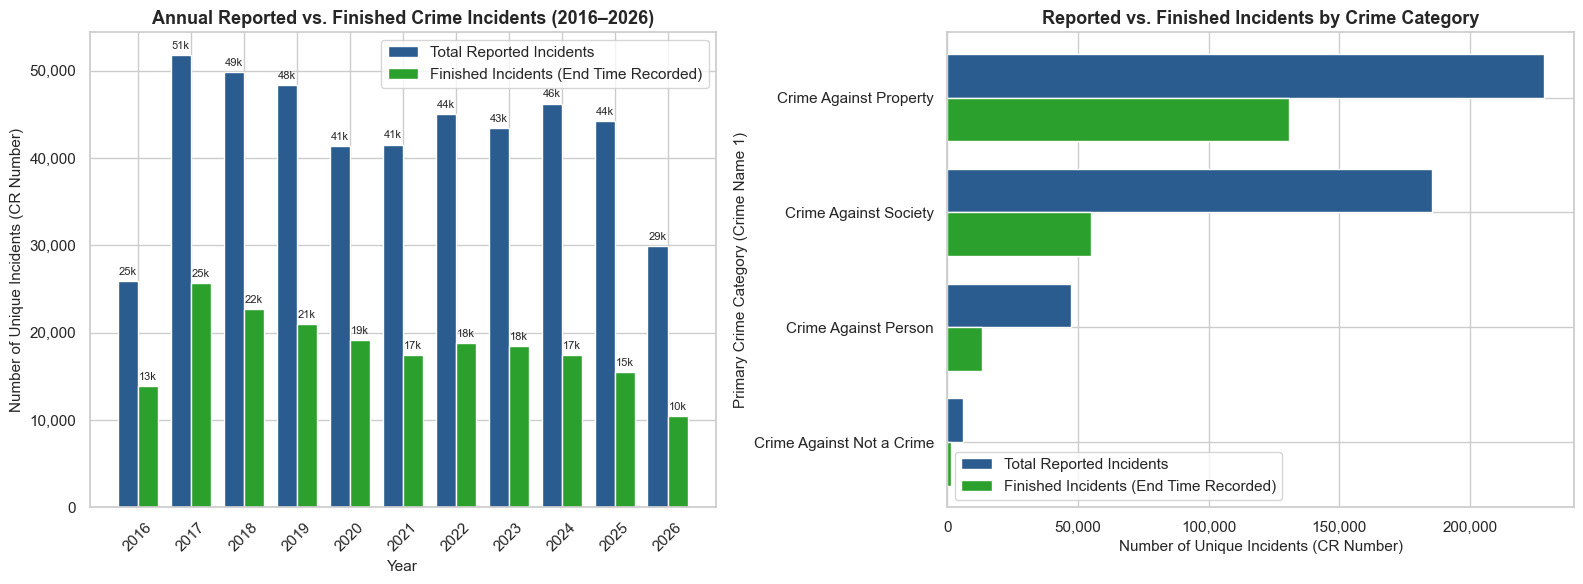

In [23]:
# 1. Ensure Year and Incident Completion Status are defined on df_clean
df_clean["Year"] = df_clean["Start Date/Time"].dt.year
df_clean["Completion_Status"] = np.where(
    df_clean["End Date/Time"].notna(),
    "Finished (End Time Recorded)",
    "Unfinished / Instantaneous (No End Time)"
)

# 2. Build Deduplicated Incident-Level Dataset (by CR Number)
df_incidents = (
    df_clean.sort_values("Start Date/Time")
    .groupby("CR Number", as_index=False)
    .agg(
        Start_Time=("Start Date/Time", "first"),
        End_Time=("End Date/Time", "max"),
        Crime_Category=("Crime Name 1", "first"),
        Year=("Year", "first"),
        Offense_Count=("Incident ID", "count")
    )
)
df_incidents["Is_Finished"] = df_incidents["End_Time"].notna()

# ==========================================
# PART A: PRINT SUMMARY STATISTICS
# ==========================================
total_offenses = len(df_clean)
finished_offenses = df_clean["End Date/Time"].notna().sum()
unfinished_offenses = total_offenses - finished_offenses

total_incidents = len(df_incidents)
finished_incidents = df_incidents["Is_Finished"].sum()
unfinished_incidents = total_incidents - finished_incidents

summary_df = pd.DataFrame({
    "Metric": [
        "Total Reported Records",
        "Finished Incidents (Valid End Date/Time)",
        "Instantaneous / No End Date/Time"
    ],
    "Offense_Level_Count": [total_offenses, finished_offenses, unfinished_offenses],
    "Offense_Level_Pct (%)": [
        100.0,
        round(finished_offenses / total_offenses * 100, 2),
        round(unfinished_offenses / total_offenses * 100, 2)
    ],
    "Unique_Incident_Count (CR)": [total_incidents, finished_incidents, unfinished_incidents],
    "Unique_Incident_Pct (%)": [
        100.0,
        round(finished_incidents / total_incidents * 100, 2),
        round(unfinished_incidents / total_incidents * 100, 2)
    ]
})

print("=== Overall Reported vs. Finished Incidents Summary ===")
print(summary_df.to_string(index=False))

# Yearly comparison table (Unique Incidents)
yearly_summary = (
    df_incidents.groupby("Year")
    .agg(
        Reported_Incidents=("CR Number", "count"),
        Finished_Incidents=("Is_Finished", "sum")
    )
    .reset_index()
)
yearly_summary["Unfinished_Instantaneous"] = (
    yearly_summary["Reported_Incidents"] - yearly_summary["Finished_Incidents"]
)
yearly_summary["Finished_Pct (%)"] = (
    yearly_summary["Finished_Incidents"] / yearly_summary["Reported_Incidents"] * 100
).round(2)

print("\n=== Yearly Reported vs. Finished Unique Incidents (2016–2026) ===")
print(yearly_summary.to_string(index=False))

# Breakdown by Crime Category
cat_summary = (
    df_incidents.groupby("Crime_Category")
    .agg(
        Reported_Incidents=("CR Number", "count"),
        Finished_Incidents=("Is_Finished", "sum")
    )
    .sort_values("Reported_Incidents", ascending=False)
    .reset_index()
)
cat_summary["Finished_Pct (%)"] = (
    cat_summary["Finished_Incidents"] / cat_summary["Reported_Incidents"] * 100
).round(2)

print("\n=== Reported vs. Finished Incidents by Crime Category ===")
print(cat_summary.to_string(index=False))

# ==========================================
# PART B: VISUALISE REPORTED VS. FINISHED
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Graph 1: Yearly Reported vs. Finished Incidents ---
x = np.arange(len(yearly_summary["Year"]))
width = 0.38

rects1 = axes[0].bar(
    x - width / 2,
    yearly_summary["Reported_Incidents"],
    width,
    label="Total Reported Incidents",
    color="#2b5c8f"
)
rects2 = axes[0].bar(
    x + width / 2,
    yearly_summary["Finished_Incidents"],
    width,
    label="Finished Incidents (End Time Recorded)",
    color="#2ca02c"
)

axes[0].set_title("Annual Reported vs. Finished Crime Incidents (2016–2026)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Year", fontsize=11)
axes[0].set_ylabel("Number of Unique Incidents (CR Number)", fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(yearly_summary["Year"].astype(int), rotation=45)
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
axes[0].legend(frameon=True)

# Add value labels on top of bars
for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f"{int(h/1000)}k", xy=(rect.get_x() + rect.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f"{int(h/1000)}k", xy=(rect.get_x() + rect.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

# --- Graph 2: Reported vs. Finished by Crime Category ---
y = np.arange(len(cat_summary["Crime_Category"]))
height = 0.38

axes[1].barh(
    y - height / 2,
    cat_summary["Reported_Incidents"],
    height,
    label="Total Reported Incidents",
    color="#2b5c8f"
)
axes[1].barh(
    y + height / 2,
    cat_summary["Finished_Incidents"],
    height,
    label="Finished Incidents (End Time Recorded)",
    color="#2ca02c"
)

axes[1].set_title("Reported vs. Finished Incidents by Crime Category", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Number of Unique Incidents (CR Number)", fontsize=11)
axes[1].set_ylabel("Primary Crime Category (Crime Name 1)", fontsize=11)
axes[1].set_yticks(y)
axes[1].set_yticklabels(cat_summary["Crime_Category"])
axes[1].invert_yaxis()  # Largest category on top
axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

In [24]:

# ---------------------------------------------------------
# 1. LOAD & PREPARE DATASET
# ---------------------------------------------------------
# Replace with your loaded DataFrame or CSV path
#df = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)

# Parse datetime columns
for col in ["Start Date/Time", "End Date/Time", "Dispatch Date/Time"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Standardize key categorical strings to prevent case-mismatch issues
str_cols = ["Crime Name 1", "Crime Name 2", "Crime Name 3", "Police District Name", "Place", "Agency"]
for col in str_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

# Feature engineering for temporal, lag, duration, and geocoding checks
df["hour"] = df["Start Date/Time"].dt.hour
df["is_weekend"] = df["Start Date/Time"].dt.dayofweek >= 5
df["dispatch_lag_mins"] = (df["Dispatch Date/Time"] - df["Start Date/Time"]).dt.total_seconds() / 60.0
df["duration_mins"] = (df["End Date/Time"] - df["Start Date/Time"]).dt.total_seconds() / 60.0
df["dispatch_missing"] = df["Dispatch Date/Time"].isna().astype(int)
df["ungeocoded"] = (
    df["Latitude"].isna() | df["Longitude"].isna() | (df["Latitude"] == 0) | (df["Longitude"] == 0)
).astype(int)

# Incident-level deduplicated view (for victim counts, spatial hotspots, and offense multiplicity)
incident_counts = df.groupby("Incident ID").size().rename("offense_count")
df = df.merge(incident_counts, on="Incident ID", how="left")
df["is_multi_offense"] = (df["offense_count"] > 1).astype(int)
df_incidents = df.drop_duplicates(subset=["Incident ID"]).copy()

# ---------------------------------------------------------
# 2. EFFECT SIZE HELPER FUNCTIONS
# ---------------------------------------------------------
def cramers_v(ct: pd.DataFrame) -> float:
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

def kruskal_epsilon_sq(h_stat: float, n: int) -> float:
    return h_stat / ((n**2 - 1) / (n + 1))

def interpret_cramers_v(v: float) -> str:
    if v < 0.10:
        return "Negligible / Small"
    elif v < 0.30:
        return "Moderate"
    return "Strong"

results = []

# ---------------------------------------------------------
# H1: Diurnal Crime Patterns (Hour vs. Top 12 Crime Name 2)
# ---------------------------------------------------------
top_c2 = df["Crime Name 2"].value_counts().nlargest(12).index
sub_h1 = df[df["Crime Name 2"].isin(top_c2) & df["hour"].notna()]
ct_h1 = pd.crosstab(sub_h1["hour"], sub_h1["Crime Name 2"])
chi2_1, p_1, dof_1, _ = stats.chi2_contingency(ct_h1)
v_1 = cramers_v(ct_h1)
results.append(["H1: Diurnal Patterns", "Chi-Square", chi2_1, p_1, f"V = {v_1:.4f}", interpret_cramers_v(v_1)])

# ---------------------------------------------------------
# H2: Weekday vs. Weekend Dynamics (Crime Name 1 & Person Share)
# ---------------------------------------------------------
valid_c1 = ["Crime Against Person", "Crime Against Property", "Crime Against Society"]
sub_h2 = df[df["Crime Name 1"].isin(valid_c1) & df["Start Date/Time"].notna()]
ct_h2 = pd.crosstab(sub_h2["is_weekend"], sub_h2["Crime Name 1"])
chi2_2, p_2, _, _ = stats.chi2_contingency(ct_h2)
v_2 = cramers_v(ct_h2)

# Two-proportion Z-test specifically for Crime Against Person share (Weekend vs Weekday)
wknd_person = ct_h2.loc[True, "Crime Against Person"]
wkdy_person = ct_h2.loc[False, "Crime Against Person"]
n_wknd = ct_h2.loc[True].sum()
n_wkdy = ct_h2.loc[False].sum()
z_2, pz_2 = proportions_ztest([wknd_person, wkdy_person], [n_wknd, n_wkdy])
results.append(["H2: Weekend vs Weekday", "Chi-Square / Z-Test", chi2_2, p_2, f"V = {v_2:.4f} (Z={z_2:.2f})", interpret_cramers_v(v_2)])

# ---------------------------------------------------------
# H3: Dispatch Response / Reporting Lag across Crime Name 1
# ---------------------------------------------------------
# Filter valid non-negative lags up to 30 days (43,200 mins) to exclude clock anomalies
sub_h3 = df[
    df["Crime Name 1"].isin(valid_c1)
    & (df["dispatch_lag_mins"] >= 0)
    & (df["dispatch_lag_mins"] <= 43200)
]
groups_h3 = [grp["dispatch_lag_mins"].values for _, grp in sub_h3.groupby("Crime Name 1")]
h_3, p_3 = stats.kruskal(*groups_h3)
eps_3 = kruskal_epsilon_sq(h_3, len(sub_h3))
results.append(["H3: Dispatch Lag", "Kruskal-Wallis", h_3, p_3, f"eps² = {eps_3:.4f}", "Non-parametric"])

# ---------------------------------------------------------
# H4: Missing Dispatch Records across Agency & Crime Name 1
# ---------------------------------------------------------
ct_h4 = pd.crosstab(df["Agency"], df["dispatch_missing"])
chi2_4, p_4, _, _ = stats.chi2_contingency(ct_h4)
v_4 = cramers_v(ct_h4)

# Logistic regression predicting missing dispatch timestamp
sub_h4_logit = df[df["Crime Name 1"].isin(valid_c1) & df["Agency"].isin(["MCPD", "RCPD", "GPD", "TPPD"])]
logit_h4 = smf.logit("dispatch_missing ~ C(Crime Name 1) + C(Agency)".replace("Crime Name 1", "Q('Crime Name 1')"), data=sub_h4_logit).fit(disp=False)
results.append(["H4: Missing Dispatch", "Chi-Square + Logit", chi2_4, p_4, f"V = {v_4:.4f}", interpret_cramers_v(v_4)])

# ---------------------------------------------------------
# H5: Offense Duration Windows (Confrontational vs Property)
# ---------------------------------------------------------
confrontational = ["Simple Assault", "Robbery", "Aggravated Assault"]
unattended_prop = ["Motor Vehicle Theft", "Theft From Motor Vehicle", "Burglary - Residential", "Burglary - Commercial"]
sub_h5 = df[(df["duration_mins"] >= 0) & (df["duration_mins"] <= 43200)].copy()
dur_conf = sub_h5[sub_h5["Crime Name 2"].isin(confrontational)]["duration_mins"]
dur_prop = sub_h5[sub_h5["Crime Name 2"].isin(unattended_prop)]["duration_mins"]
u_5, p_5 = stats.mannwhitneyu(dur_prop, dur_conf, alternative="greater")
r_rb_5 = 1 - (2 * u_5) / (len(dur_prop) * len(dur_conf))  # Rank-biserial correlation
results.append(["H5: Offense Duration", "Mann-Whitney U", u_5, p_5, f"Med: {dur_prop.median():.1f}m vs {dur_conf.median():.1f}m", "Directional"])

# ---------------------------------------------------------
# H6: District Crime Composition (Police District Name vs Crime Name 1)
# ---------------------------------------------------------
main_districts = [
    "SILVER SPRING", "BETHESDA", "WHEATON", "GERMANTOWN",
    "MONTGOMERY VILLAGE", "ROCKVILLE", "TAKOMA PARK"
]
sub_h6 = df[
    df["Police District Name"].str.upper().isin(main_districts)
    & df["Crime Name 1"].isin(valid_c1)
]
ct_h6 = pd.crosstab(sub_h6["Police District Name"].str.upper(), sub_h6["Crime Name 1"])
chi2_6, p_6, _, _ = stats.chi2_contingency(ct_h6)
v_6 = cramers_v(ct_h6)
results.append(["H6: District Composition", "Chi-Square", chi2_6, p_6, f"V = {v_6:.4f}", interpret_cramers_v(v_6)])

# ---------------------------------------------------------
# H7: Micro-Spatial Hotspot Clustering across PRAs
# ---------------------------------------------------------
pra_counts = df_incidents["PRA"].dropna()
pra_counts = pra_counts[pra_counts.astype(str).str.strip() != ""].value_counts()
chi2_7, p_7 = stats.chisquare(pra_counts.values)
top10_share = pra_counts.nlargest(int(len(pra_counts) * 0.10)).sum() / pra_counts.sum()
results.append(["H7: PRA Spatial Hotspots", "Chi-Square GoF", chi2_7, p_7, f"Top 10% PRA = {top10_share:.1%}", "High Concentration"])

# ---------------------------------------------------------
# H8: Premise-to-Offense Association (Top 15 Place vs Top 12 Crime Name 2)
# ---------------------------------------------------------
top_places = df["Place"].value_counts().nlargest(15).index
sub_h8 = df[df["Place"].isin(top_places) & df["Crime Name 2"].isin(top_c2)]
ct_h8 = pd.crosstab(sub_h8["Place"], sub_h8["Crime Name 2"])
chi2_8, p_8, _, _ = stats.chi2_contingency(ct_h8)
v_8 = cramers_v(ct_h8)
results.append(["H8: Premise vs Offense", "Chi-Square", chi2_8, p_8, f"V = {v_8:.4f}", interpret_cramers_v(v_8)])

# ---------------------------------------------------------
# H9: Victim Count Severity across Crime Name 1 (Incident Level)
# ---------------------------------------------------------
sub_h9 = df_incidents[df_incidents["Crime Name 1"].isin(valid_c1) & df_incidents["Victims"].notna()]
groups_h9 = [grp["Victims"].values for _, grp in sub_h9.groupby("Crime Name 1")]
h_9, p_9 = stats.kruskal(*groups_h9)
eps_9 = kruskal_epsilon_sq(h_9, len(sub_h9))
results.append(["H9: Victim Severity", "Kruskal-Wallis", h_9, p_9, f"eps² = {eps_9:.4f}", "Incident-level"])

# ---------------------------------------------------------
# H10: Multi-Offense Co-Occurrence by Offense Type
# ---------------------------------------------------------
sub_h10 = df[df["Crime Name 2"].isin(top_c2)]
ct_h10 = pd.crosstab(sub_h10["Crime Name 2"], sub_h10["is_multi_offense"])
chi2_10, p_10, _, _ = stats.chi2_contingency(ct_h10)
v_10 = cramers_v(ct_h10)
results.append(["H10: Multi-Offense Co-occur", "Chi-Square", chi2_10, p_10, f"V = {v_10:.4f}", interpret_cramers_v(v_10)])

# ---------------------------------------------------------
# H11: Jurisdictional Agency Differences (MCPD, RCPD, GPD, TPPD)
# ---------------------------------------------------------
agencies = ["MCPD", "RCPD", "GPD", "TPPD"]
sub_h11 = df[df["Agency"].isin(agencies) & df["Crime Name 1"].isin(valid_c1)]
ct_h11 = pd.crosstab(sub_h11["Agency"], sub_h11["Crime Name 1"])
chi2_11, p_11, _, _ = stats.chi2_contingency(ct_h11)
v_11 = cramers_v(ct_h11)
results.append(["H11: Agency Differences", "Chi-Square", chi2_11, p_11, f"V = {v_11:.4f}", interpret_cramers_v(v_11)])

# ---------------------------------------------------------
# H12: Geocoding Completeness Bias (0,0 Coordinates vs Crime Name 2)
# ---------------------------------------------------------
sub_h12 = df[df["Crime Name 2"].isin(top_c2)]
ct_h12 = pd.crosstab(sub_h12["Crime Name 2"], sub_h12["ungeocoded"])
chi2_12, p_12, _, _ = stats.chi2_contingency(ct_h12)
v_12 = cramers_v(ct_h12)
results.append(["H12: Geocoding Bias", "Chi-Square", chi2_12, p_12, f"V = {v_12:.4f}", interpret_cramers_v(v_12)])

# ---------------------------------------------------------
# 3. COMPILE SUMMARY TABLE WITH MULTIPLE-TESTING CORRECTION
# ---------------------------------------------------------
results_df = pd.DataFrame(
    results,
    columns=["Hypothesis", "Statistical_Test", "Test_Statistic", "Raw_p_value", "Effect_Size", "Magnitude"]
)

# Apply Bonferroni correction across all 12 simultaneous hypotheses
reject, p_bonf, _, _ = multipletests(results_df["Raw_p_value"], alpha=0.05, method="bonferroni")
results_df["Bonferroni_p_value"] = p_bonf
results_df["Reject_H0 (alpha=0.05)"] = reject

#print(results_df.to_string(index=False))
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 30)
pd.set_option('display.min_rows', 30)
display(results_df)

# Optional: Print group medians/means for H3, H5, H9, and odds ratios for H4
print("\n--- H3 Median Dispatch Lag (mins) ---")
#print(sub_h3.groupby("Crime Name 1")["dispatch_lag_mins"].agg(["count", "median", "mean"]))
display(sub_h3.groupby("Crime Name 1")["dispatch_lag_mins"].agg(["count", "median", "mean"]))

print("\n--- H9 Mean & Max Victims per Incident ---")
#print(sub_h9.groupby("Crime Name 1")["Victims"].agg(["count", "mean", "median", "max"]))
display(sub_h9.groupby("Crime Name 1")["Victims"].agg(["count", "mean", "median", "max"]))

print("\n--- H4 Logistic Regression Odds Ratios (Missing Dispatch) ---")
#print(np.exp(logit_h4.params).rename("Odds_Ratio"))
display(np.exp(logit_h4.params).rename("Odds_Ratio"))

,Hypothesis,Statistical_Test,Test_Statistic,Raw_p_value,Effect_Size,Magnitude,Bonferroni_p_value,Reject_H0 (alpha=0.05)
0,H1: Diurnal Patterns,Chi-Square,7.850230e+04,0.000000e+00,V = 0.1332,Moderate,0.000000e+00,True
1,H2: Weekend vs Weekday,Chi-Square / Z-Test,6.967771e+02,4.974784e-152,V = 0.0373 (Z=26.37),Negligible / Small,5.969741e-151,True
2,H3: Dispatch Lag,Kruskal-Wallis,5.574305e+04,0.000000e+00,eps² = 0.1457,Non-parametric,0.000000e+00,True
3,H4: Missing Dispatch,Chi-Square + Logit,8.071434e+02,5.332821e-170,V = 0.0399,Negligible / Small,6.399385e-169,True
4,H5: Offense Duration,Mann-Whitney U,5.559753e+08,0.000000e+00,Med: 720.0m vs 21.0m,Directional,0.000000e+00,True
5,H6: District Composition,Chi-Square,6.517428e+03,0.000000e+00,V = 0.0807,Negligible / Small,0.000000e+00,True
6,H7: PRA Spatial Hotspots,Chi-Square GoF,1.083098e+06,0.000000e+00,Top 10% PRA = 45.8%,High Concentration,0.000000e+00,True
7,H8: Premise vs Offense,Chi-Square,5.577396e+05,0.000000e+00,V = 0.4130,Strong,0.000000e+00,True
8,H9: Victim Severity,Kruskal-Wallis,7.158519e+04,0.000000e+00,eps² = 0.1551,Incident-level,0.000000e+00,True
9,H10: Multi-Offense Co-occur,Chi-Square,2.283828e+04,0.000000e+00,V = 0.2382,Moderate,0.000000e+00,True



--- H3 Median Dispatch Lag (mins) ---


,count,median,mean
Crime Name 1,,,
Crime Against Person,44013,0.750000,640.684486
Crime Against Property,198526,389.291667,2489.701908
Crime Against Society,140002,0.750000,998.351634



--- H9 Mean & Max Victims per Incident ---


,count,mean,median,max
Crime Name 1,,,,
Crime Against Person,47583,1.204359,1.0,22
Crime Against Property,228483,1.000000,1.0,1
Crime Against Society,185456,1.000000,1.0,1



--- H4 Logistic Regression Odds Ratios (Missing Dispatch) ---


Intercept                                         0.133971
C(Q('Crime Name 1'))[T.Crime Against Property]    1.084258
C(Q('Crime Name 1'))[T.Crime Against Society]     1.570427
C(Agency)[T.MCPD]                                 1.033751
C(Agency)[T.RCPD]                                 0.675190
C(Agency)[T.TPPD]                                 0.655065
Name: Odds_Ratio, dtype: float64

1. research question
2. hyperthisis
3. Anylisis [data visuales]
4. Conclusion based on hyperthisis

### What is the Rapidly happening crime in the Area (Crime Patterns) and what is the penal code used against the depended

In [31]:
# Load the approved shared dataset
#df_shared = pd.read_parquet("data/processed/cw1_shared_v1.parquet")
df_rq = df.copy()

# Select relevant columns for crime pattern & offense code analysis
cols = [
    "Incident ID", "Offense Code", "NIBRS Code",
    "Crime Name 1", "Crime Name 2", "Crime Name 3",
    "Police District Name", "Start Date/Time"
]
df_analysis = df_rq[cols].copy()

# Extract Year (exclude partial years 2016 and 2026 when measuring full-year growth rates)
df_analysis["Year"] = df_analysis["Start Date/Time"].dt.year

print(df_analysis)

        Incident ID Offense Code NIBRS Code            Crime Name 1  \
0         201590757         9108        90Z   Crime Against Society   
1         201590749         2901        290  Crime Against Property   
2         201590742         9199        90Z   Crime Against Society   
3         201590754         9108        90Z   Crime Against Society   
4         201590766         9199        90Z   Crime Against Society   
5         201590741         2902        290  Crime Against Property   
6         201590733         9105        90Z   Crime Against Society   
7         201590735         2610        26F  Crime Against Property   
8         201590739         9107        90Z   Crime Against Society   
9         201590738         1399        13B    Crime Against Person   
10        201590732         2902        290  Crime Against Property   
11        201590748         1399        13B    Crime Against Person   
12        201590727         1399        13B    Crime Against Person   
13    

In [30]:
# Load the approved shared dataset
#df_shared = pd.read_parquet("data/processed/cw1_shared_v1.parquet")
df_rq = df.copy()

# Select relevant columns for crime pattern & offense code analysis
cols = [
    "Incident ID", "Offense Code", "NIBRS Code",
    "Crime Name 1", "Crime Name 2", "Crime Name 3",
    "Police District Name", "Start Date/Time"
]
df_analysis = df_rq[cols].copy()

# Extract Year (exclude partial years 2016 and 2026 when measuring full-year growth rates)
df_analysis["Year"] = df_analysis["Start Date/Time"].dt.year

# 1. Top 10 Offense Codes & NIBRS Codes overall (2016–2026)
top_offenses = (
    df_analysis.groupby(["Offense Code", "NIBRS Code", "Crime Name 2", "Crime Name 3"])
    .size()
    .reset_index(name="Offense_Count")
    .sort_values("Offense_Count", ascending=False)
)
top_offenses["Share_%"] = (top_offenses["Offense_Count"] / len(df_analysis) * 100).round(2)
display(top_offenses.head(10))

# 2. Fastest-growing offenses across full calendar years (2017 vs. 2025)
df_full_years = df_analysis[df_analysis["Year"].between(2017, 2025)]
yearly_counts = (
    df_full_years.groupby(["Crime Name 2", "Year"])
    .size()
    .unstack(fill_value=0)
)

# Filter offenses with at least 500 cases in 2017 to avoid small-base distortion
significant_crimes = yearly_counts[yearly_counts[2017] >= 500].copy()
significant_crimes["Growth_Rate_%"] = (
    (significant_crimes[2025] - significant_crimes[2017]) / significant_crimes[2017] * 100
).round(2)

display(significant_crimes[[2017, 2021, 2025, "Growth_Rate_%"]].sort_values("Growth_Rate_%", ascending=False).head(10))

,Offense Code,NIBRS Code,Crime Name 2,Crime Name 3,Offense_Count,Share_%
105,2305,23F,Theft From Motor Vehicle,LARCENY - FROM AUTO,41308,8.13
103,2303,23C,Shoplifting,LARCENY - SHOPLIFTING,35011,6.89
356,9199,90Z,All Other Offenses,POLICE INFORMATION,33174,6.53
74,1399,13B,Simple Assault,ASSAULT - 2ND DEGREE,31826,6.26
115,2399,23H,All other Larceny,LARCENY (DESCRIBE OFFENSE),20699,4.07
161,2902,290,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - PRIVATE,19814,3.90
355,9113,90Z,All Other Offenses,MENTAL ILLNESS - EMERGENCY PETITION,19739,3.88
299,5404,90D,Driving Under the Influence,DRIVING UNDER THE INFLUENCE LIQUOR,19420,3.82
347,9105,90Z,All Other Offenses,LOST PROPERTY,17917,3.53
119,2404,240,Motor Vehicle Theft,AUTO THEFT - VEHICLE THEFT,17262,3.40


Year,2017,2021,2025,Growth_Rate_%
Crime Name 2,,,,
Motor Vehicle Theft,909,1433,2323,155.56
Theft of Motor Vehicle Parts or Accessories,812,1632,1532,88.67
Shoplifting,2599,2435,4742,82.45
Identity Theft,766,2677,1120,46.21
Aggravated Assault,648,827,765,18.06
False Pretenses/Swindle/Confidence Game,925,1193,1004,8.54
Simple Assault,3489,3401,3770,8.05
Runaway,683,432,733,7.32
All Other Offenses,12204,11920,12734,4.34


In [26]:
from scipy.stats import chi2_contingency

# Focus on the top 8 crime categories and valid named police districts
top_8_crimes = df_analysis["Crime Name 2"].value_counts().head(8).index
df_spatial = df_analysis[
    df_analysis["Crime Name 2"].isin(top_8_crimes) &
    df_analysis["Police District Name"].notna()
]

contingency_table = pd.crosstab(df_spatial["Police District Name"], df_spatial["Crime Name 2"])
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

# Calculate Cramer's V for effect size
n = contingency_table.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency_table.shape) - 1)))

print(f"Chi-Square Statistic: {chi2:,.2f}")
print(f"Degrees of Freedom: {dof}")
print(f"p-value: {p_val:.4e}")
print(f"Cramer's V: {cramers_v:.4f}")

Chi-Square Statistic: 11,924.71
Degrees of Freedom: 56
p-value: 0.0000e+00
Cramer's V: 0.0710


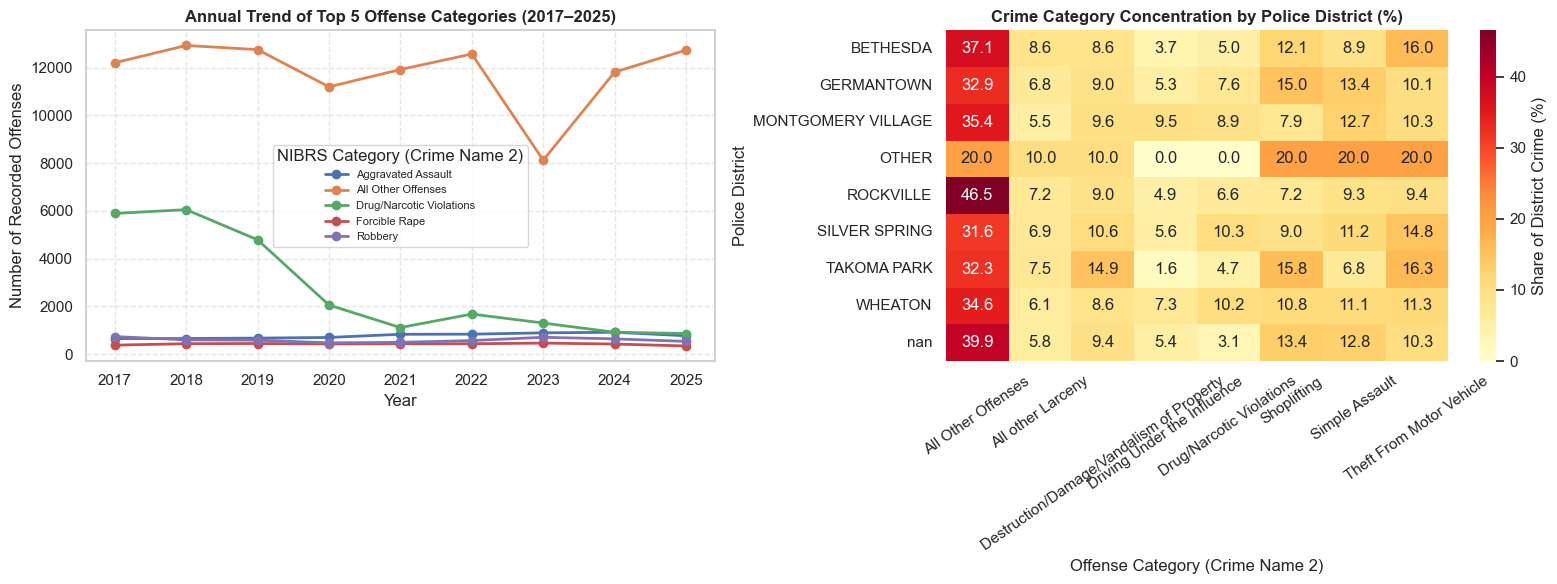

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualisation 1: Year-over-Year Trajectory of Top 5 Rapidly Occurring Offenses (2017–2025)
top_5_names = top_offenses["Crime Name 2"].value_counts().head(5).index
trend_data = (
    df_full_years[df_full_years["Crime Name 2"].isin(top_5_names)]
    .groupby(["Year", "Crime Name 2"])
    .size()
    .unstack()
)
trend_data.plot(ax=axes[0], marker="o", linewidth=2)
axes[0].set_title("Annual Trend of Top 5 Offense Categories (2017–2025)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Recorded Offenses")
axes[0].legend(title="NIBRS Category (Crime Name 2)", fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Visualisation 2: District-Level Concentration Heatmap (Row-Normalized %)
district_pct = pd.crosstab(
    df_spatial["Police District Name"],
    df_spatial["Crime Name 2"],
    normalize="index"
) * 100

sns.heatmap(district_pct, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Share of District Crime (%)"})
axes[1].set_title("Crime Category Concentration by Police District (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Offense Category (Crime Name 2)")
axes[1].set_ylabel("Police District")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()